### Projecto Final: Previsão de Churn - Interconnect
Previsão da taxa de cancelamento dos clientes (churn) da empresa de telecomunicações Interconnect, para mitigar o problema, e com uma métrica AUC-ROC de 0.85.

In [14]:
#pip install xgboost 

### 1. Inicialização e carregamento dos Dados

In [64]:
# Importando as livrarias necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
# silenciando os avisos (warnings) do código
warnings.filterwarnings('ignore')

# Importando as livrarias do sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, precision_score

In [ ]:
# Leitura dos datasets
df_contract = pd.read_csv('data/contract.csv')
df_internet = pd.read_csv('data/internet.csv')
df_personal = pd.read_csv('data/personal.csv')
df_phone = pd.read_csv('data/phone.csv')

### 2. Análise exploratória dos dados (EDA)

In [17]:
# Verificação básica dos datasets 
print("Contratos:")
print(df_contract.sample(5))
print("Internet:")
print(df_internet.sample(5))
print("Pessoal:")
print(df_personal.sample(5))
print("Telefone:")
print(df_phone.sample(5))

Contratos:
      customerID   BeginDate              EndDate            Type  \
5765  1265-XTECC  2014-02-01  2019-10-01 00:00:00        One year   
6311  3162-KKZXO  2015-07-01                   No        One year   
5992  0687-ZVTHB  2014-05-01  2019-10-01 00:00:00        One year   
407   0111-KLBQG  2017-06-01                   No  Month-to-month   
4992  7740-KKCXF  2015-11-01                   No  Month-to-month   

     PaperlessBilling            PaymentMethod  MonthlyCharges TotalCharges  
5765              Yes  Credit card (automatic)           96.55       6581.9  
6311              Yes         Electronic check          100.15      5409.75  
5992               No  Credit card (automatic)           72.45      4653.85  
407               Yes             Mailed check           93.95      2861.45  
4992              Yes  Credit card (automatic)           30.05      1529.45  
Internet:
      customerID InternetService OnlineSecurity OnlineBackup DeviceProtection  \
2169  1229-RCAL

- Consegue-se constactar, que de facto todas as tabelas partilham da coluna "customerID"
- Os tamanhos das tabelas são diferentes

In [18]:
# Informações gerais dos datasets
print("#"*50)
print("Informações do dataset de contratos:")
print(df_contract.info())
print("="*50)
print("Informações do dataset de internet:")
print(df_internet.info())
print("="*50)
print("Informações do dataset pessoal:")
print(df_personal.info())
print("="*50)
print("Informações do dataset de telefone:")
print(df_phone.info())
# Informações de estatísticas descritivas dos datasets
print("#"*50)
print("Estatísticas descritivas do dataset de contratos:")
print(df_contract.describe())
print("="*50)
print("Estatísticas descritivas do dataset de internet:")
print(df_internet.describe())
print("="*50)
print("Estatísticas descritivas do dataset pessoal:")
print(df_personal.describe())
print("="*50)
print("Estatísticas descritivas do dataset de telefone:")
print(df_phone.describe())


##################################################
Informações do dataset de contratos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB
None
Informações do dataset de internet:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   obje

- Analisou-se todas as tabels e foi possível notar que: 
    - contracts: Tem tipos de dados; object e float
    - internet: Tem tipos de dados; object
    - pessoal: Tem tipoes de dados; object e int
    - phone: Tem tipos de dados; object
- As tabelas não são do mesmo tamanho e possuem números de colunas e linhas diferentes

In [19]:
# Verificação de valores nulos nos datasets
print("#"*50)
print("Valores nulos no dataset de contratos:")
print(df_contract.isnull().sum())
print("="*50)
print("Valores nulos no dataset de internet:")
print(df_internet.isnull().sum())
print("="*50)
print("Valores nulos no dataset pessoal:")
print(df_personal.isnull().sum())
print("="*50)
print("Valores nulos no dataset de telefone:")
print(df_phone.isnull().sum())

##################################################
Valores nulos no dataset de contratos:
customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64
Valores nulos no dataset de internet:
customerID          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64
Valores nulos no dataset pessoal:
customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64
Valores nulos no dataset de telefone:
customerID       0
MultipleLines    0
dtype: int64


- Não existem valores nulos nas tabelas ácima referenciadas

In [20]:
for nome, tabela in {'contract': df_contract, 'personal': df_personal,
                     'internet': df_internet, 'phone': df_phone}.items():
    print(nome, tabela.shape)
    tabela.info()

print((df_contract['EndDate'] != 'No').mean())  # proporção de clientes que cancelaram

contract (7043, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB
personal (7043, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partne

In [21]:
# Junção das tabelas em um único dataframe, utilizando a coluna 'customerID' como chave
df = df_contract.merge(df_internet, on='customerID', how='left') \
                .merge(df_personal, on='customerID', how='left') \
                .merge(df_phone, on='customerID', how='left')

In [22]:
# Analise estatística inicial e distribuição dos recursos dos clientes, incluindo a verificação de valores nulos e tipos de dados
print("#"*50)
print("Informações do dataframe combinado:")
print(df.info())
print("="*50)
print("Estatísticas descritivas do dataframe combinado:")
print(df.describe())
print("="*50)
# Verificação de valores nulos no dataframe combinado
print("Valores nulos no dataframe combinado:")
print(df.isnull().sum())
print("="*50)
print("Tipos de dados no dataframe combinado:")
print(df.dtypes)
print("="*50)
print("Número de linhas e colunas no dataframe combinado:")
print(df.shape)
print("="*50)
print("Número de linhas duplicadas no dataframe combinado:")
print(df.duplicated().sum())
print("="*50)
print("Número de linhas únicas no dataframe combinado:")
print(df.nunique())


##################################################
Informações do dataframe combinado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
 8   InternetService   5517 non-null   object 
 9   OnlineSecurity    5517 non-null   object 
 10  OnlineBackup      5517 non-null   object 
 11  DeviceProtection  5517 non-null   object 
 12  TechSupport       5517 non-null   object 
 13  StreamingTV       5517 non-null   object 
 14  StreamingMovies   5517 non-null   object 
 15  ge

- Após fazer o merge das colunas, a estrutura original das tabelas tende a modificar
- Agora existe apenas um df e composto por 20 colunas e 7043 linhas
- Agora aparecem valores nulos nas seguintes colunas: InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies e MultipleLines. Por conscidencia, estes dados em falta são originários das tabelas "internet" com um shape=5517 por 8 e "phone" com um shape=6360 por 2.
- Fazendo os calculos de dados nulos no dataset final, nota-se que é a diferença existente antes e depois do merge dos vários datasets.

#### 2a) Tratamento e Limpeza dos dados

In [23]:
# Conversão de TotalCharges para "float"
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce') # Converter para numérico
# Identificar e tratar os novos clientes
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("#"*50)
print("Certificando-se que os valores estão conformes: ")
print(df['TotalCharges'].dtype)
print("="*30)
print(f"Valores nulos: {df['TotalCharges'].isna().sum()}")

##################################################
Certificando-se que os valores estão conformes: 
float64
Valores nulos: 0


- Já não existem valores nulos na tabela "TotalCharges"

In [24]:
# Substituindo os nulos em "internet" e "phone" por "No"
colunas_servicos = [
    'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines'
]

df[colunas_servicos] = df[colunas_servicos].fillna('No')

# Certificar de como está o dataset
print("Tabelas de Internet e phone: ")
print(df.isna().sum())

Tabelas de Internet e phone: 
customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
MultipleLines       0
dtype: int64


- Já não existem valores nulos em "internet" e "phone"

In [25]:
# Tratamento dos dados BeginDate e EndDate
df['status'] = (df['EndDate'] != 'No').astype(int)
df['BeginDate'] = pd.to_datetime(df['BeginDate'])

# Conversão do EndDate
df['EndDate'] = pd.to_datetime(df['EndDate'], errors='coerce') # Controlando para quebrar assim que aparecer 'No'


In [26]:
print(df['status'].sample(5))
print("="*50)
print(df['BeginDate'].sample(5))
print("="*50)
print(df['EndDate'].sample(10))

2347    0
3739    0
2126    0
2929    0
542     0
Name: status, dtype: int64
3733   2018-01-01
6977   2018-02-01
546    2016-09-01
2420   2019-10-01
4203   2019-07-01
Name: BeginDate, dtype: datetime64[ns]
1081          NaT
5591   2019-12-01
1145          NaT
5191          NaT
641    2019-12-01
6734   2020-01-01
3677          NaT
6023          NaT
2251          NaT
4306          NaT
Name: EndDate, dtype: datetime64[ns]


In [27]:
# Contando quantos NaT existem em EndDate
qtd_nat = df['EndDate'].isna().sum()
print(f"NaT existentes em EndDate: {qtd_nat}")

NaT existentes em EndDate: 5174


In [28]:
# Encontrando a data referência
data_max = max(df['BeginDate'].max(), df['EndDate'].max())

In [29]:
print(f"A data de Referência encontrada é: {data_max}")

A data de Referência encontrada é: 2020-02-01 00:00:00


In [30]:
df['tempo_como_cliente'] = np.where(
    df['EndDate'].isna(),
    data_max - df['BeginDate'], # Caso seja NaT ( cliente activo)
    df['EndDate'] - df['BeginDate'] # Caso não seja NaT (cliente cancelado)
)

# Contando quantos clientes possuem status == 0
qtd_ativos = (df['status'] == 0).sum()

print(f"Qunatidade de clientes ativos (status == 0): {qtd_ativos}")

Qunatidade de clientes ativos (status == 0): 5174


In [31]:
print(f"Tempo como cliente : \n{df['tempo_como_cliente'].sample(10)}")

Tempo como cliente : 
5409    791 days
6564    153 days
1187   2163 days
60     1432 days
3649   2163 days
2001    153 days
346      61 days
291    1067 days
5613   2191 days
1389   1033 days
Name: tempo_como_cliente, dtype: timedelta64[ns]


In [32]:
# Convertendo o tempo para um número inteiro (de modos a ser utilizado em gráficos e ML)
df['dias_como_cliente'] = df['tempo_como_cliente'].dt.days

In [33]:
print(f"Dias como cliente - em valor numérico apenas:\n{df['dias_como_cliente'].sample(10)}")

Dias como cliente - em valor numérico apenas:
5623    1218
5786    2191
4205     730
5643      30
6888      92
517      153
1709     914
1128     822
2990     306
3313      31
Name: dias_como_cliente, dtype: int64


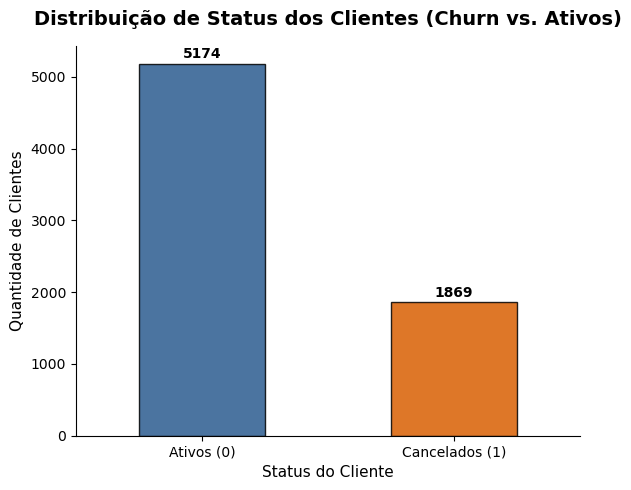

In [34]:
# Contando os dados
cont_status = df['status'].value_counts()

# Configurando a figura e estilo das barras
plt.figure(figsize=(6, 5))
bars = cont_status.plot(
    kind='bar', 
    color=['#2b5c8f', '#d95f02'],  # Azul sóbrio para ativos, laranja/vermelho para churn
    edgecolor='black',
    alpha=0.85
)

# Títulos e rótulos limpos
plt.title('Distribuição de Status dos Clientes (Churn vs. Ativos)', fontsize=14, pad=15, fontweight='bold')
plt.ylabel('Quantidade de Clientes', fontsize=11)
plt.xlabel('Status do Cliente', fontsize=11)

# Substitui o 0 e 1 originais por nomes explicativos e deixa na horizontal (0 graus)
plt.xticks(ticks=[0, 1], labels=['Ativos (0)', 'Cancelados (1)'], rotation=0, fontsize=10)

# Remove as bordas desnecessárias (topo e direita) para um visual moderno
for spine in ['top', 'right']:
    plt.gca().spines[spine].set_visible(False)

# 4. Adiciona os valores exatos em cima de cada barra (Data Labels)
for bar in bars.patches:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2, 
        yval + (yval * 0.01),  # Pequeno espaço acima da barra
        f'{int(yval)}', 
        ha='center', 
        va='bottom', 
        fontsize=10, 
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

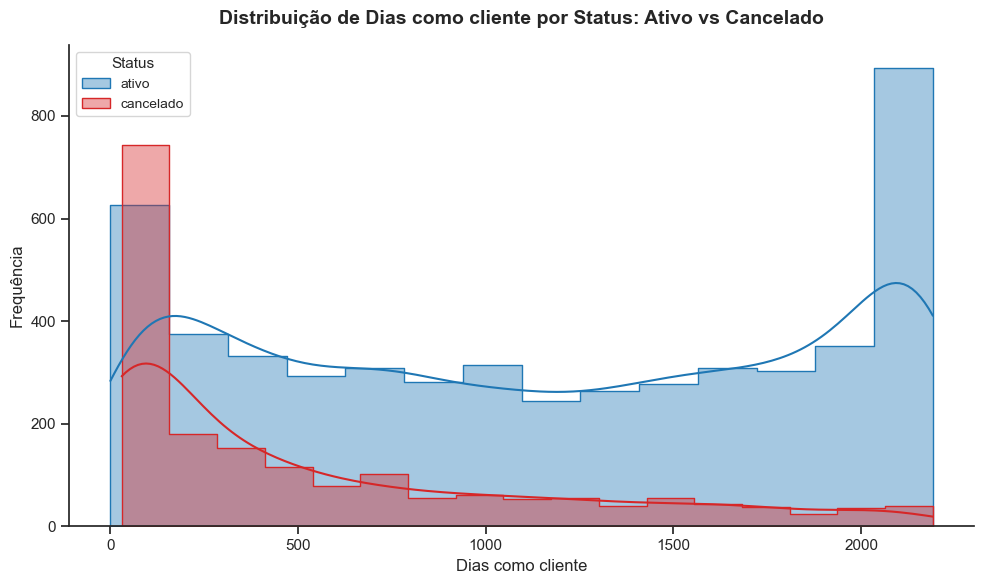

In [35]:
# Histograma de dias como cliente
status_0 = df[df['status'] == 0]
status_1 = df[df['status'] == 1]

# Definição do tamanho e estilo do gráfico
plt.figure(figsize=(10, 6))
sns.set_theme(style="ticks")

# Plotagem do histograma utlizando o Kernel Density Estimates (KDE) para uma distribuição das curvas mais suave
sns.histplot(
    data=status_0, 
    x='dias_como_cliente', 
    color='#1f77b4', 
    label='ativo', 
    alpha=0.4, 
    kde=True, 
    element='step'
)

sns.histplot(
    data=status_1, 
    x='dias_como_cliente', 
    color='#d62728', 
    label='cancelado', 
    alpha=0.4, 
    kde=True, 
    element='step'
)

# Clean and informative titles/labels
plt.title('Distribuição de Dias como cliente por Status: Ativo vs Cancelado', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Dias como cliente', fontsize=12)
plt.ylabel('Frequência', fontsize=12)

# Redefinição da legenda
plt.legend(title='Status', title_fontsize='11', fontsize='10', frameon=True)
sns.despine()

plt.tight_layout()
plt.show()



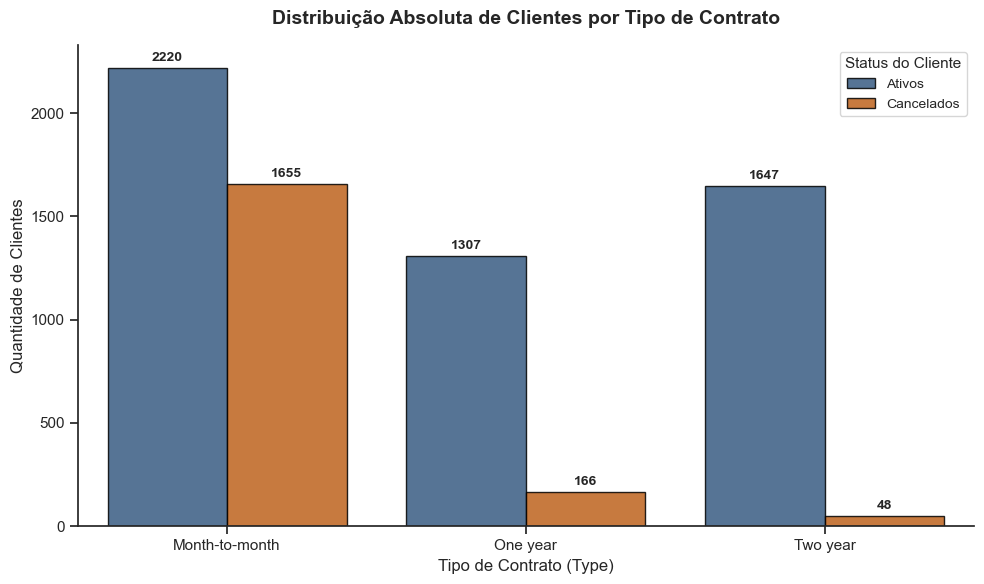

In [36]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="ticks")

# Palette: Azul, para Ativo, Coral/Red para Churn
custom_palette = {0: '#2b5c8f', 1: '#d95f02'}

# Countplot
ax = sns.countplot(
    data=df, 
    x='Type', 
    hue='status', 
    palette=custom_palette,
    edgecolor='black',
    alpha=0.85
)

# Titlo e axis labels
plt.title('Distribuição Absoluta de Clientes por Tipo de Contrato', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Tipo de Contrato (Type)', fontsize=12)
plt.ylabel('Quantidade de Clientes', fontsize=12)

# Legenda
handles, labels = ax.get_legend_handles_labels()
plt.legend(
    handles=handles, 
    labels=['Ativos', 'Cancelados'], 
    title='Status do Cliente', 
    title_fontsize='11', 
    fontsize='10', 
    frameon=True
)

# Removendo borders
sns.despine()

# Adicionando valores
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
    
        if height > 0:
            ax.annotate(
                f'{int(height)}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', 
                va='bottom', 
                fontsize=10, 
                fontweight='bold'
            )
plt.tight_layout()
plt.show()


In [38]:
# Checando 
df[df['TotalCharges'] == 0]['dias_como_cliente'].describe()

count    11.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: dias_como_cliente, dtype: float64

- O resultado ácima ilustrado, confirma a hipótese de que 11 clientes com TotalCharges == 0 têm dias_como_cliente igual a 0 em todos os casos.

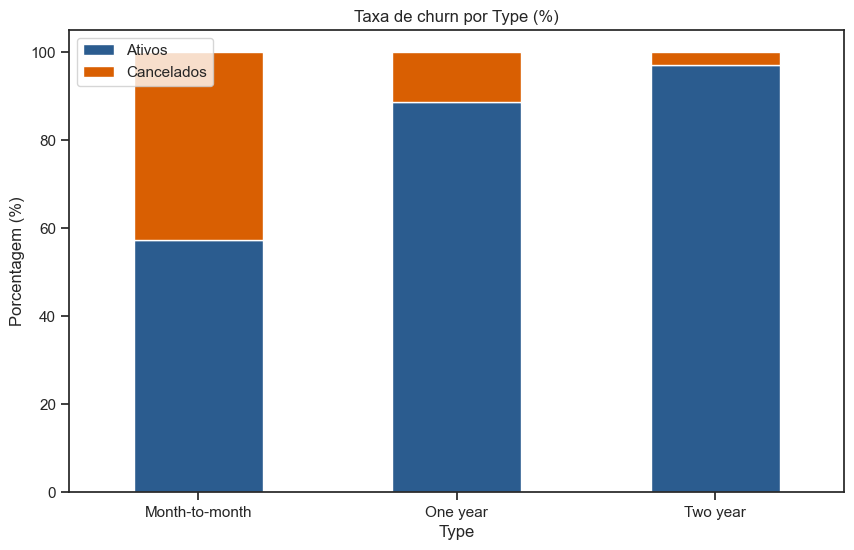

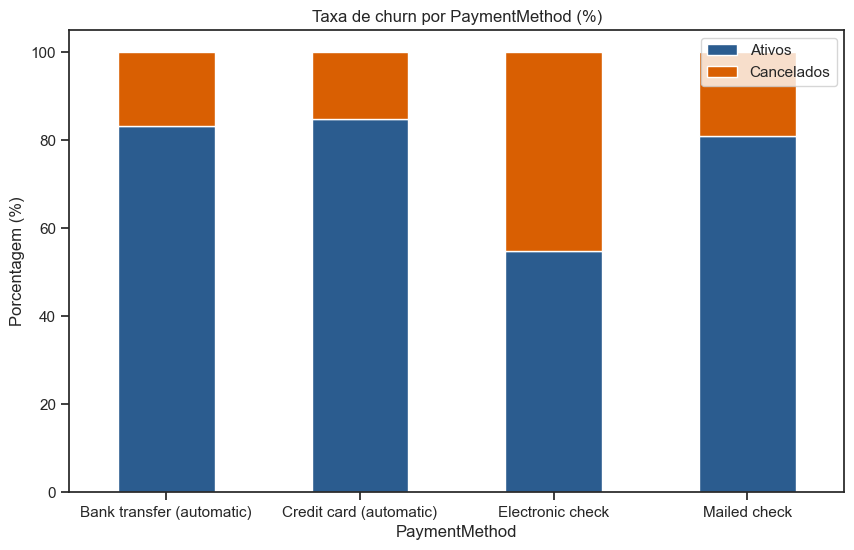

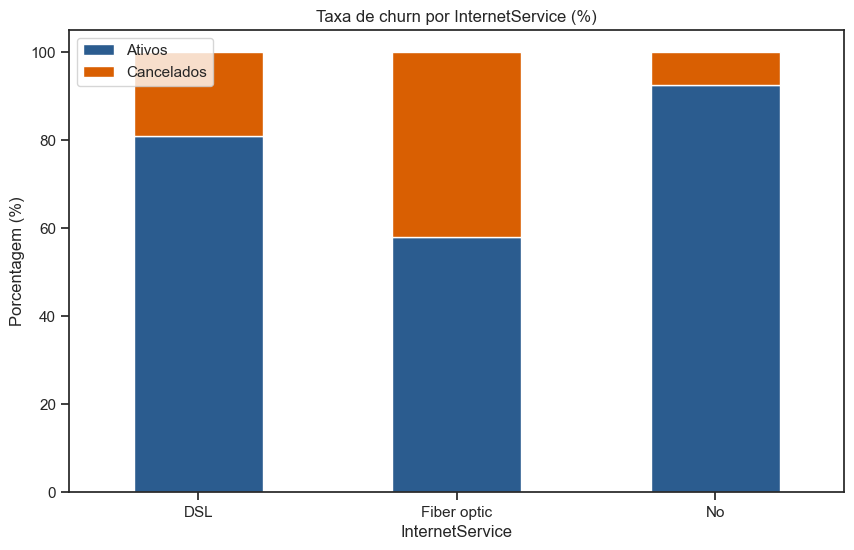

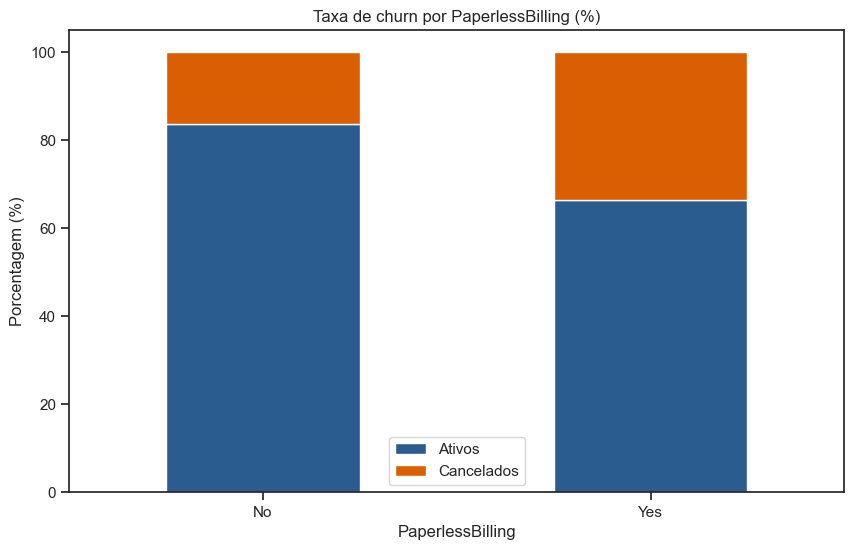

In [42]:
def grafico_churn(coluna, titulo):
    prop = pd.crosstab(df[coluna], df['status'], normalize='index') * 100
    ax = prop.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], figsize=(10, 6))
    ax.set_title(titulo)
    ax.set_ylabel('Porcentagem (%)')
    ax.legend(['Ativos', 'Cancelados'])
    plt.xticks(rotation=0)
    plt.show()

for coluna in ['Type', 'PaymentMethod', 'InternetService', 'PaperlessBilling']:
    grafico_churn(coluna, f'Taxa de churn por {coluna} (%)')

In [27]:
# Proporção de 0s e 1s
df['status'].value_counts(normalize=True) * 100 # Percentagem de 0s e 1s

0    73.463013
1    26.536987
Name: status, dtype: float64

#### Constatação do desbalancemaneto
- Consegue-se notar um desbalanceamento relevante das classes, mostrando que quase 3 em cada 4 clientes são ativos, e só 1 em cada 4 cancelou, mas não foi preciso ser tratado porque a meta foi atingida.
- Nota-se que permanecendo deste jeito, este desbalanceamento pode fazer o modelo "preguiçoso", beneficiando mais os ativos em detrimento dos inativos.
- De modos a dar seguimento ao trabalho, deve-se tratar os dados, usando class_weight='balanced' ou as técnicas oversampling/SMOTE na etapa de treinamento. 

<div class="alert alert-block alert-warning">
<b>Comentário:</b> <a class="tocSkip"></a>

Aqui foi escrito que o desbalanceamento seria tratado com `class_weight='balanced'` ou com sobreamostragem, mas os modelos mais abaixo foram treinados com os parâmetros padrão: nenhum deles recebe `class_weight`. Vale fazer uma das duas coisas:

- aplicar de fato e comparar o resultado:

```python
model_lr = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
model_rf = RandomForestClassifier(random_state=42, class_weight='balanced')
# no XGBoost o equivalente é scale_pos_weight = (quantidade de 0) / (quantidade de 1)
model_xgb = XGBClassifier(random_state=42, eval_metric='logloss',
                          scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum())
```

- ou ajustar o texto para dizer que o desbalanceamento foi identificado, mas não precisou ser tratado porque a meta foi atingida. "Neste caso, ajustou-se o texto"

O importante é que o notebook, a conclusão e o relatório digam a mesma coisa.
</div>

### 3. Etapa de Execução

In [43]:
# Verificação de colunas categóricas 
df.dtypes

customerID                     object
BeginDate              datetime64[ns]
EndDate                datetime64[ns]
Type                           object
PaperlessBilling               object
PaymentMethod                  object
MonthlyCharges                float64
TotalCharges                  float64
InternetService                object
OnlineSecurity                 object
OnlineBackup                   object
DeviceProtection               object
TechSupport                    object
StreamingTV                    object
StreamingMovies                object
gender                         object
SeniorCitizen                   int64
Partner                        object
Dependents                     object
MultipleLines                  object
status                          int64
tempo_como_cliente    timedelta64[ns]
dias_como_cliente               int64
dtype: object

In [44]:
df.select_dtypes(include='object').nunique()

customerID          7043
Type                   3
PaperlessBilling       2
PaymentMethod          4
InternetService        3
OnlineSecurity         2
OnlineBackup           2
DeviceProtection       2
TechSupport            2
StreamingTV            2
StreamingMovies        2
gender                 2
Partner                2
Dependents             2
MultipleLines          2
dtype: int64

In [45]:
# Criação de lista com colunas categoricas com yes e no
lista_yesno = ['PaperlessBilling', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
               'TechSupport', 'StreamingTV', 'StreamingMovies', 'Partner', 'Dependents', 'MultipleLines']

In [46]:
for coluna in lista_yesno:
    df[coluna] = df[coluna].map({'Yes': 1, 'No': 0})

In [47]:
df[lista_yesno].head()

,PaperlessBilling,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Partner,Dependents,MultipleLines
0,1,0,1,0,0,0,0,1,0,0
1,0,1,0,1,0,0,0,0,0,0
2,1,1,1,0,0,0,0,0,0,0
3,0,1,0,1,1,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0


In [48]:
df['gender'] = df['gender'].map({'Male':1, 'Female':0})
df['gender'].head()

0    0
1    1
2    1
3    1
4    0
Name: gender, dtype: int64

In [49]:
col_categoricas = ['Type', 'PaymentMethod', 'InternetService']
df = pd.get_dummies(df, columns=col_categoricas)

In [50]:
# Removendo colunas para ter o dataset final para dar seguimento ao projeto
df = df.drop(columns=['customerID', 'BeginDate', 'EndDate', 'tempo_como_cliente'])
df.head()

,PaperlessBilling,MonthlyCharges,TotalCharges,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,gender,...,Type_Month-to-month,Type_One year,Type_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,1,29.85,29.85,0,1,0,0,0,0,0,...,True,False,False,False,False,True,False,True,False,False
1,0,56.95,1889.50,1,0,1,0,0,0,1,...,False,True,False,False,False,False,True,True,False,False
2,1,53.85,108.15,1,1,0,0,0,0,1,...,True,False,False,False,False,False,True,True,False,False
3,0,42.30,1840.75,1,0,1,1,0,0,1,...,False,True,False,True,False,False,False,True,False,False
4,1,70.70,151.65,0,0,0,0,0,0,0,...,True,False,False,False,False,True,False,False,True,False


In [51]:
# Pegando target
X = df.drop(columns=['status'])
y = df['status']

#### Separando as variáveis

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

#### Treinamento do modelo

In [57]:
# Inicialização dos modelos 
model_rf = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42))
model_rf.fit(X_train, y_train)

# Treinando Linear Regression
print("Treinamento do modelo de Regressão Liniear...")
model_lr.fit(X_train, y_train)

# Treinamento Random Forest
print("Treinamento do modelo de Random Forest...")
model_rf.fit(X_train, y_train)

# Gerando as predições
preds_lr = model_lr.predict(X_test)
preds_rf = model_rf.predict(X_test)

print("✅ Ambos modelos treinados com sucesso!")

Treinamento do modelo de Regressão Liniear...
Treinamento do modelo de Random Forest...
✅ Ambos modelos treinados com sucesso!


#### Estatística dos modelos

Logistic Regression AUC-ROC: 0.8431
Random Forest AUC-ROC: 0.8441


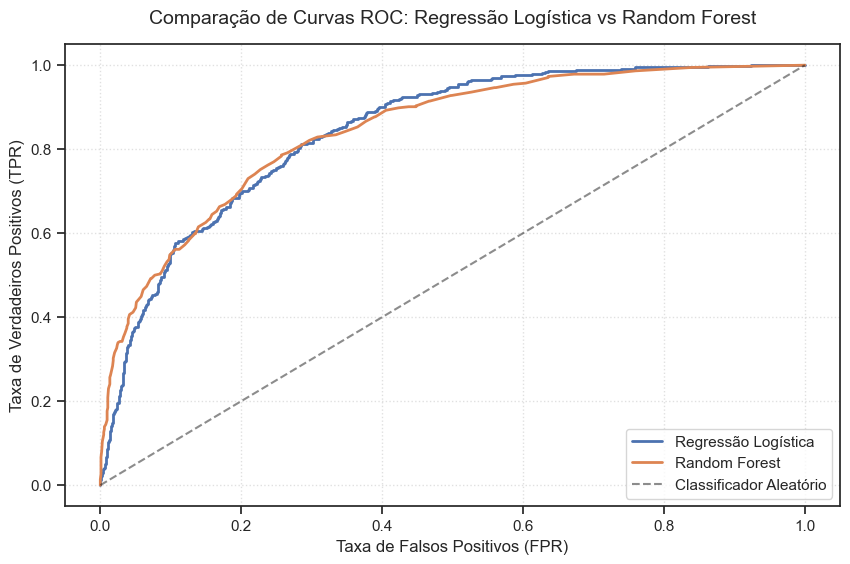

In [58]:
# Pegando as probabilidades para a class positiva (churn = 1)
# [:, 1] Extraindo a segunda coluna, que possui a probabilidade de churn
probs_lr = model_lr.predict_proba(X_test)[:, 1]
probs_rf = model_rf.predict_proba(X_test)[:, 1]

# ROC-AUC Score
auc_lr = roc_auc_score(y_test, probs_lr)
auc_rf = roc_auc_score(y_test, probs_rf)

# ROC-CURVE-lr
fpr_lr, tpr_lr, thresholds = roc_curve(y_test, probs_lr)

# ROC-CURVE-rf
fpr_rf, tpr_rf, thresholds = roc_curve(y_test, probs_rf)

print(f"Logistic Regression AUC-ROC: {auc_lr:.4f}")
print(f"Random Forest AUC-ROC: {auc_rf:.4f}")
##########################################################################################################
# Gráfico ROC-CURVE

# Cria uma única figura com tamanho adequado
plt.figure(figsize=(10, 6))

# Plota ambas as curvas no mesmo gráfico para comparação direta
plt.plot(fpr_lr, tpr_lr, label='Regressão Logística', linewidth=2)
plt.plot(fpr_rf, tpr_rf, label='Random Forest', linewidth=2)

# Adiciona a linha de referência (diagonal) comum em curvas ROC
plt.plot([0, 1], [0, 1], 'k--', label='Classificador Aleatório', alpha=0.5)

# Configurações de títulos e eixos (essenciais para gráficos profissionais)
plt.title('Comparação de Curvas ROC: Regressão Logística vs Random Forest', fontsize=14, pad=15)
plt.xlabel('Taxa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)', fontsize=12)

# Ativa elementos visuais auxiliares
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=11) # Legenda no canto inferior direito

# Exibe o gráfico finalizado
plt.show()

- Apesar de não atingir o valor esperado de 0.85, ainda assim este é um resultado bom por estar muito próximo do esperado
- E os modelos bases servem extamente para isso, justificando que os dados estão preparados

#### Gradiente Boosting

Treinando XGBoost Classifier...
XGBoost Classifeir AUC-ROC: 0.9053


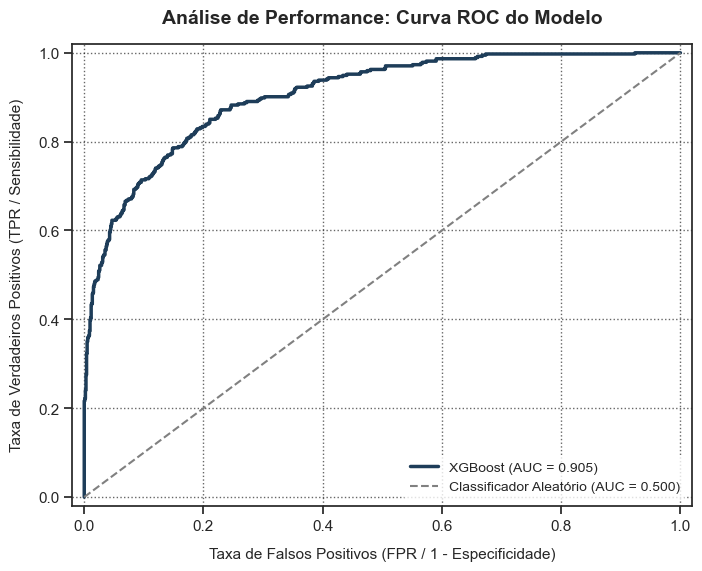

In [59]:
# Inicialização do modelo
model_xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

# Treinamento do modelo nos dados de treinamento
print("Treinando XGBoost Classifier...")
model_xgb.fit(X_train, y_train)

# Pegando a probabilidade para a classe positiva (Class = 1) para o ROC curve
probs_xgb = model_xgb.predict_proba(X_test)[:, 1]

# ROC-AUC Score
auc_xgb = roc_auc_score(y_test, probs_xgb)

# ROC-CURVE
fpr_xgb, tpr_xgb, thresholds = roc_curve(y_test, probs_xgb)

print(f"XGBoost Classifeir AUC-ROC: {auc_xgb:.4f}")

##########################################################################
# Gráfico

# Configura a área de desenho e proporção ideal (quadrada ou retangular leve)
plt.figure(figsize=(8, 6))

# Plota a curva do XGBoost incluindo o valor de AUC formatado na legenda
plt.plot(fpr_xgb, tpr_xgb, color='#1e3d59', linewidth=2.5, 
         label=f'XGBoost (AUC = {auc_xgb:.3f})')

# Linha de referência diagonal (classificador aleatório / no-skill)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, 
         label='Classificador Aleatório (AUC = 0.500)')

# Títulos claros e tamanho de fonte legível
plt.title('Análise de Performance: Curva ROC do Modelo', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Taxa de Falsos Positivos (FPR / 1 - Especificidade)', fontsize=11, labelpad=10)
plt.ylabel('Taxa de Verdadeiros Positivos (TPR / Sensibilidade)', fontsize=11, labelpad=10)

# Ajustes de limites dos eixos para evitar distorções visuais
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])

# Elementos de suporte (Grade discreta e Legenda posicionada perfeitamente)
plt.grid(True, linestyle=':', alpha=0.6, color='black')
plt.legend(loc='lower right', fontsize=10, frameon=True, facecolor='white', edgecolor='none')

# Exibe o resultado final de forma limpa
plt.show()


In [60]:
# Confirmação se houve ou não sorte da divisão dos dados, utilizando validação cruzada (cross-validation) com 5 folds e a métrica ROC-AUC para avaliação do modelo XGBoost. A média e o desvio padrão das pontuações são calculados e exibidos para fornecer uma visão geral da performance do modelo em diferentes subconjuntos dos dados de treinamento.
scores = cross_val_score(XGBClassifier(random_state=42, eval_metric='logloss'),
                         X_train, y_train, cv=5, scoring='roc_auc')
print(scores.mean(), scores.std())

0.9020220448712527 0.007306104863246759


- O resultado do XGBoost, ultrapassada a meta definida de 0.85, obtendo assim 0.9084.
- Desta feita, achou-se melhorar não avançar para a otimização de hiperparâmetros.
- Tendo em conta os resultados ácima registrados, segue-se agora a avaliação final do modelo usando matriz de confusão e a conclusão.
- Nota-se que não houve sorte da divisão dos dados, porque o valor depois de efetuar a validação cruzada é o mesmo.

#### Avaliação final do modelo, usando matriz de confusão

In [61]:
# convertendo probabilidades para binários
preds_xgb = (probs_xgb >= 0.5).astype(int)

In [62]:
# Calculando os valores de Matriz
cm = confusion_matrix(y_test, preds_xgb)

# Extraindo de maneira segura os componente individuais 
tn, fp, fn, tp = cm.ravel()

# Display "base metrics"
print("--- Matriz de Confusão (Valores Brutos) ---")
print(f"Verdadeiros Negativos (Ativos previstos corretamente): {tn}")
print(f"Falsos Positivos (Ativos previstos como Churn):       {fp}")
print(f"Falsos Negativos (Churn previstos como Ativos):       {fn}")
print(f"Verdadeiros Positivos (Churn previstos corretamente):  {tp}")
print("\nFormato de Matriz Tradicional (Array): ")
print(cm)


--- Matriz de Confusão (Valores Brutos) ---
Verdadeiros Negativos (Ativos previstos corretamente): 972
Falsos Positivos (Ativos previstos como Churn):       63
Falsos Negativos (Churn previstos como Ativos):       136
Verdadeiros Positivos (Churn previstos corretamente):  238

Formato de Matriz Tradicional (Array): 
[[972  63]
 [136 238]]


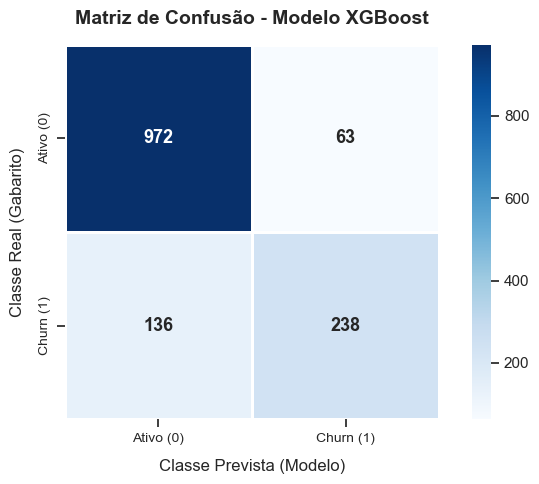

In [63]:
# Set up 
plt.figure(figsize=(7, 5))
sns.set_theme(style="ticks")

# Criação do heatmap
sns.heatmap(
    cm, 
    annot=True,          
    fmt='d',             
    cmap='Blues',        
    cbar=True,           
    square=True,         
    linewidths=1,        
    linecolor='white',
    annot_kws={"size": 13, "weight": "bold"} 
)

# Labels descritiva
plt.title('Matriz de Confusão - Modelo XGBoost', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Classe Prevista (Modelo)', fontsize=12, labelpad=10)
plt.ylabel('Classe Real (Gabarito)', fontsize=12, labelpad=10)

# Substituição generica de 0 e 1 com os nomes de negócio
plt.xticks(ticks=[0.5, 1.5], labels=['Ativo (0)', 'Churn (1)'], fontsize=10)
plt.yticks(ticks=[0.5, 1.5], labels=['Ativo (0)', 'Churn (1)'], fontsize=10, va='center')

plt.tight_layout()
plt.show()


- 982, clientes que ficaram ativos e o modelo realmente acertou com a sua previsão de "ativo" - verdadeiro negativo
- 53, clientes que ficaram ativos, mas o modelo errou prevendo "churn" - falso positivo - alarme falso
- 141, clientes que de facto cancelaramm moas o modelo errou, prevendo "ativo" - falso negativo - erro caro porque a empresa perde chance de tentar reter esse cliente antes que ele abandone
- 233, cliente que cancelaram e o modelo acertou, prevendo "churn" - o verdadeiro positivo - exatamente o que a interconnect quer identificar, para agir a tempo.
- O modelo acerta bem mais do que erra (982 + 233= 1215 acertos em 1409 casos), mas ainda assim o erro mais relevante do negócio é o grupo dos 141 Falso Negativos, por serem clientes em risco que passaram despercebidos.

In [65]:
for limiar in [0.5, 0.4, 0.3]: # Testando diferentes limiares de decisão
    preds = (probs_xgb >= limiar).astype(int)
    print(limiar, 'recall:', round(recall_score(y_test, preds), 3),
          'precisão:', round(precision_score(y_test, preds), 3))

0.5 recall: 0.636 precisão: 0.791
0.4 recall: 0.709 precisão: 0.734
0.3 recall: 0.77 precisão: 0.665


In [66]:
# Calculando a acuracia
accuracy_xgb =accuracy_score(y_test, preds_xgb)

print(f"XGBoost Accuracy: {accuracy_xgb:.4f}")
print(f"Acurácia Geral: {accuracy_xgb * 100:.2f}%")

XGBoost Accuracy: 0.8588
Acurácia Geral: 85.88%


### 4. Conclusão 

#### Objetivo: 
- Este projeto teve como objetivo principal, o desenvolvimento de um modelo de machine learning capaz de prever o churn de clientes da empresa Interconnect, com meta de AUC-ROC igual ou superior a 0.85.
#### Resumo geral:
- Preparação dos dados:
  - Preparou-se os dados conforme requisitado, que culminou com o merge de 4 tabelas pela coluna custiomerID
  - Os valores nulos gerados pelo merge, foram tratados, as datas foram convertidas e foi criada a coluna dias_como_cliente
  - As classes mostraram-se desbalanceadas, foram identificadas e documentas
- Engengaria de recursos:
  - O dataset final com 26 colunas númericas, pronto para modelagem
- Modelagem:
  - Foram treinados e comparados 3 modelos - Regressão Logística, Random Forest e XGBoost. O XGBoost teve o melhor desempenho, com AUC-ROC de 0.9084, superando a meta.
- Avaliação:
  - A matriz de confusão foi calculada (982 VN, 53 FP, 141 FN, 233 VP) e acurácia de 86.23%, sendo os Falsos Negativos são o erro mais crítico para o negócio.

#### Respostas as Perguntas:
- Os valores nulos gerados após o merge das 4 tabelas, foram tratados. Para o caso das tabelas 'internet' e 'phone', tinham um shape diferente do resto das tabelas e os valores nulos são a diferença existente entre as entradas das duas tabelas em questão e o resto das tabelas onde se fez o merge. Neste caso os nulos foram substituidos por 'No' e no TotalCharge foi substituído por '0'.
- Quanto as tabelas BeginDate e EndDate: EndDate, tem uma mistura de datas reais e texto 'No'. Sendo 'No' um formato não data, utilizou-se o errors='coerce', para em caso de se encontrar algum valor que não seja do formato data, o mesmo já não gere erro, e substitui por NaT (Not a Time).
- No caso da tabela TotalCharge: os valores em branco representam clientes com menos de 1 mês de contracto. Foram identificados 11 entradas e os mesmos foram preenchidos com valores '0', como de resto foi confirmado com a utilização do '.describe'.


#### Projeto Churn - Assinatura
<div style="text-align: right; margin-top: 50px; font-style: italic;">
  <p>Assinado por: <strong>André Wilson Vicente Neto</strong></p>
</div>